# Travel Reimbursement Approval Agent

Prototype agent that reviews travel reimbursement claims against the policy in Appendix A and returns one of
APPROVE, PARTIAL_APPROVE, REJECT or MANUAL_REVIEW for each claim, with amounts, missing documents, policy references
and an explanation.

## README

### Setup

```bash
python -m venv .venv
.venv\Scripts\activate            # Windows
source .venv/bin/activate         # macOS / Linux
pip install -r requirements.txt   # or let the first code cell install the packages
```

### Environment variables

| Variable | Required | Notes |
|---|---|---|
| `GROQ_API_KEY` | yes, for the LLM agent | Free key from https://console.groq.com/keys |
| `GROQ_MODEL` | no | Default `openai/gpt-oss-120b` |

Put them in a `.env` file next to the notebook (copy `.env.example`).

### Running

Open the notebook and use Kernel > Restart & Run All. No other steps are needed.

If `GROQ_API_KEY` is missing, or the API fails, the notebook still completes. It uses the same tools with a
deterministic rule engine instead of the LLM, and each explanation is prefixed with the mode that produced it.

### How it is organised

1. Policy rules (with their POL ids) and numeric limits
2. Claim intake: the five Appendix B claims, validated with Pydantic
3. Tools: policy lookup, eligibility, receipts, per-diem limits, approval threshold, timeliness
4. Rule engine, used as the cross-check and the fallback
5. LLM agent (LangChain + Groq) that chooses which tools to call
6. Validation of the agent's answer
7. Evaluation of all claims, audit trail, tests
8. Dashboard
9. Design Notes & Reasoning
10. Final JSON results (last cell)

### Key design choices

- The LLM decides which tools to call and writes the explanation. All amounts are calculated in Python tools.
- Every agent answer is cross-checked against the rule engine. If they disagree, the claim goes to manual review.
- Anything ambiguous, missing or conflicting goes to manual review instead of being forced into a decision.

In [1]:
%pip install -q langchain langchain-groq pydantic python-dotenv pandas matplotlib ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: D:\New folder\hcl\travel-reimbursement-agent\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import json
import os
import re
import time
from collections import defaultdict
from datetime import date
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
from pydantic import BaseModel, Field, ValidationError

try:
    from dotenv import find_dotenv, load_dotenv
    load_dotenv(find_dotenv(usecwd=True))
except ImportError:
    pass

GROQ_API_KEY = os.getenv("GROQ_API_KEY", "").strip()
GROQ_MODEL = os.getenv("GROQ_MODEL", "openai/gpt-oss-120b")
USE_LLM = bool(GROQ_API_KEY)

print("Mode:", f"LLM agent ({GROQ_MODEL})" if USE_LLM else "rule engine only (GROQ_API_KEY not set)")

Mode: LLM agent (openai/gpt-oss-120b)


## 1. Policy and limits

Rules are stored with their POL ids so they can be cited. `topics` are the keywords `policy_lookup` matches on.
The numbers live in `LIMITS` so the tools don't have to parse them out of text.

In [3]:
POLICY = {
    "POL-CAT-01": {
        "title": "Eligible categories",
        "topics": ["eligible", "category", "airfare", "lodging", "hotel", "meals", "ground", "transport", "taxi", "conference", "registration"],
        "text": "Reimbursable when incurred for a documented business purpose: airfare (economy class only, see POL-AIR-01), "
                "lodging (hotel room charges), meals (subject to per-diem limits, see POL-PD-01), ground transport "
                "(taxi, rideshare, train, rental car, parking), conference / registration fees.",
    },
    "POL-CAT-02": {
        "title": "Ineligible items",
        "topics": ["ineligible", "alcohol", "minibar", "spa", "gym", "entertainment", "movies", "shopping", "gifts", "fines", "penalties", "personal"],
        "text": "Never reimbursable; rejected (deducted in full): alcohol and minibar charges; spa, gym and personal "
                "entertainment; in-room movies, personal shopping, gifts; traffic fines, penalties and late fees; "
                "any personal (non-business) expense.",
    },
    "POL-PD-01": {
        "title": "Meals",
        "topics": ["meals", "meal", "per-diem", "perdiem", "food", "dinner", "limit", "cap"],
        "text": "Meals: maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.",
    },
    "POL-PD-02": {
        "title": "Lodging",
        "topics": ["lodging", "hotel", "night", "per-diem", "limit", "cap"],
        "text": "Lodging: maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.",
    },
    "POL-PD-03": {
        "title": "Ground transport",
        "topics": ["ground", "transport", "taxi", "rideshare", "train", "rental", "parking", "per-diem", "limit", "cap"],
        "text": "Ground transport: maximum $50 per day. Amounts above the cap are deducted.",
    },
    "POL-AIR-01": {
        "title": "Airfare class",
        "topics": ["airfare", "flight", "class", "business", "first", "economy"],
        "text": "Only economy class airfare is reimbursable. Business/first-class fares are a policy exception and must be "
                "routed to Manual Review (not auto-deducted, because a pre-approval may exist).",
    },
    "POL-RCT-01": {
        "title": "Receipt required above $25",
        "topics": ["receipt", "documentation", "itemized"],
        "text": "Any single line item greater than $25 requires an attached, itemized receipt. Airfare and lodging always "
                "require a receipt regardless of amount.",
    },
    "POL-RCT-02": {
        "title": "Missing receipt handling",
        "topics": ["receipt", "missing", "documentation"],
        "text": "If a receipt is missing for an item that requires one, the item is not silently rejected; the claim is "
                "routed to Manual Review so the reviewer can request the receipt.",
    },
    "POL-APR-01": {
        "title": "Auto-approve tier",
        "topics": ["approval", "threshold", "tier", "auto"],
        "text": "Total <= $500: may be auto-approved by the agent if fully compliant.",
    },
    "POL-APR-02": {
        "title": "Manager tier",
        "topics": ["approval", "threshold", "tier", "manager"],
        "text": "Total > $500 and <= $2,000: eligible for approval, treated as approvable when fully compliant.",
    },
    "POL-APR-03": {
        "title": "Director / Manual-Review tier",
        "topics": ["approval", "threshold", "tier", "director", "high", "value"],
        "text": "Total > $2,000: exceeds the agent's auto-approval authority and must be routed to Manual Review "
                "(director approval required), even if otherwise compliant.",
    },
    "POL-TIME-01": {
        "title": "Submission window",
        "topics": ["timeliness", "late", "submission", "window", "deadline"],
        "text": "Claims must be submitted within 30 days of the expense date. Late claims are routed to Manual Review.",
    },
}

DECISION_GUIDANCE = (
    "APPROVE: every item eligible, all receipts present, all within per-diem, total within an approvable tier "
    "(POL-APR-01 / POL-APR-02). "
    "PARTIAL_APPROVE: the claim is valid but some amounts exceed per-diem caps or some items are ineligible; "
    "reimburse up to the cap and deduct the rest. "
    "REJECT: the claimed items are ineligible (POL-CAT-02) with nothing reimbursable. "
    "MANUAL_REVIEW: any ambiguity, policy exception, high value (POL-APR-03), missing required receipt (POL-RCT-02), "
    "late submission or conflicting information. Prefer MANUAL_REVIEW over forcing a decision."
)

LIMITS = {
    "meals_per_day": 75.00,
    "lodging_per_night": 200.00,
    "ground_transport_per_day": 50.00,
    "receipt_threshold": 25.00,
    "auto_approve_max": 500.00,
    "manager_max": 2000.00,
    "submission_window_days": 30,
}

GROUND_CATEGORIES = {"ground_transport", "taxi", "rideshare", "train", "rental_car", "parking"}
ELIGIBLE_CATEGORIES = {"airfare", "lodging", "meals", "conference_fees"} | GROUND_CATEGORIES
INELIGIBLE_CATEGORIES = {"alcohol", "minibar", "spa", "gym", "entertainment", "in_room_movies", "movies",
                         "personal_shopping", "shopping", "gifts", "gift", "fines", "penalties", "late_fees", "personal"}
INELIGIBLE_KEYWORDS = {
    "minibar": r"\bmini-?bar\b",
    "alcohol": r"\b(alcohol|wine|beer|liquor|bar tab)\b",
    "spa": r"\bspa\b",
    "gym": r"\bgym\b",
    "in-room movies": r"\bmovies?\b",
    "shopping": r"\bshopping\b",
    "gift": r"\bgifts?\b",
    "fine/penalty": r"\b(fines?|penalt(y|ies)|late fees?)\b",
}
RECEIPT_ALWAYS = {"airfare", "lodging"}

print(len(POLICY), "rules:", ", ".join(POLICY))

12 rules: POL-CAT-01, POL-CAT-02, POL-PD-01, POL-PD-02, POL-PD-03, POL-AIR-01, POL-RCT-01, POL-RCT-02, POL-APR-01, POL-APR-02, POL-APR-03, POL-TIME-01


## 2. Claim intake

The five claims from Appendix B, unchanged. Nights and days are not entered separately. The per-diem tool reads them
from the description ("2 nights", "3 days") and compares them with the trip dates.

In [4]:
class LineItem(BaseModel):
    item_id: str
    category: str
    description: str
    amount: float = Field(ge=0)
    receipt_attached: bool


class Claim(BaseModel):
    claim_id: str
    employee: str
    purpose: str
    trip_start: date
    trip_end: date
    submitted: date
    line_items: list[LineItem]

    @property
    def total(self) -> float:
        return round(sum(i.amount for i in self.line_items), 2)


RAW_CLAIMS = [
    {"claim_id": "CLM-001", "employee": "A. Rivera", "purpose": "Attend 2-day industry conference (business)",
     "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20",
     "line_items": [
         {"item_id": "CLM-001-1", "category": "airfare", "description": "Round-trip economy airfare", "amount": 420.00, "receipt_attached": True},
         {"item_id": "CLM-001-2", "category": "lodging", "description": "Hotel, 2 nights @ $180", "amount": 360.00, "receipt_attached": True},
         {"item_id": "CLM-001-3", "category": "meals", "description": "Meals, 3 days @ ~$60/day", "amount": 180.00, "receipt_attached": True},
         {"item_id": "CLM-001-4", "category": "conference_fees", "description": "Conference registration", "amount": 150.00, "receipt_attached": True},
     ]},
    {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
     "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25",
     "line_items": [
         {"item_id": "CLM-002-1", "category": "spa", "description": "Hotel spa package", "amount": 300.00, "receipt_attached": True},
         {"item_id": "CLM-002-2", "category": "minibar", "description": "In-room minibar", "amount": 80.00, "receipt_attached": True},
     ]},
    {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
     "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22",
     "line_items": [
         {"item_id": "CLM-003-1", "category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt_attached": True},
         {"item_id": "CLM-003-2", "category": "lodging", "description": "Hotel, 2 nights @ $250", "amount": 500.00, "receipt_attached": True},
         {"item_id": "CLM-003-3", "category": "meals", "description": "Meals, 2 days @ $70/day", "amount": 140.00, "receipt_attached": True},
     ]},
    {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)",
     "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28",
     "line_items": [
         {"item_id": "CLM-004-1", "category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt_attached": True},
         {"item_id": "CLM-004-2", "category": "lodging", "description": "Hotel, 3 nights", "amount": 600.00, "receipt_attached": False},
     ]},
    {"claim_id": "CLM-005", "employee": "E. Haddad", "purpose": "Client dinner / business development",
     "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24",
     "line_items": [
         {"item_id": "CLM-005-1", "category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt_attached": False},
     ]},
]

CLAIMS = [Claim.model_validate(c) for c in RAW_CLAIMS]
CLAIMS_BY_ID = {c.claim_id: c for c in CLAIMS}

pd.DataFrame([{"claim_id": c.claim_id, "employee": c.employee, "purpose": c.purpose,
               "trip": f"{c.trip_start} to {c.trip_end}", "submitted": c.submitted,
               "items": len(c.line_items), "total_claimed": c.total} for c in CLAIMS])

,claim_id,employee,purpose,trip,submitted,items,total_claimed
0,CLM-001,A. Rivera,Attend 2-day industry conference (business),2026-06-10 to 2026-06-12,2026-06-20,4,1110.0
1,CLM-002,B. Osei,Weekend hotel stay,2026-06-14 to 2026-06-15,2026-06-25,2,380.0
2,CLM-003,C. Nakamura,Client site visit (business),2026-06-08 to 2026-06-10,2026-06-22,3,940.0
3,CLM-004,D. Fischer,International vendor negotiation (business),2026-06-16 to 2026-06-18,2026-06-28,2,3000.0
4,CLM-005,E. Haddad,Client dinner / business development,2026-06-11 to 2026-06-11,2026-06-24,1,220.0


## 3. Tools

Plain Python functions. Each returns its findings, the POL ids it applied and a one-line summary.

| Tool | Rules | Checks |
|---|---|---|
| `policy_lookup(topic)` | any | Returns the policy rules matching a topic |
| `check_eligibility` | POL-CAT-01, POL-CAT-02, POL-AIR-01 | Ineligible items, business/first-class airfare, unknown categories |
| `check_receipts` | POL-RCT-01, POL-RCT-02 | Required receipts that are missing |
| `check_per_diem_limits` | POL-PD-01, 02, 03 | Caps per day/night, nights vs trip dates, group meals |
| `check_approval_threshold` | POL-APR-01, 02, 03 | Tier for the total after deductions |
| `check_timeliness` | POL-TIME-01 | 30-day submission window |

In [5]:
def _norm(category: str) -> str:
    return category.strip().lower().replace(" ", "_").replace("-", "_")


def _uniq(items):
    return list(dict.fromkeys(items))


def _trip_days(c: Claim) -> int:
    return (c.trip_end - c.trip_start).days + 1


def _trip_nights(c: Claim) -> int:
    return max((c.trip_end - c.trip_start).days, 1)


def _stated_units(description: str, unit: str) -> int | None:
    # "Hotel, 2 nights @ $180" -> 2
    m = re.search(rf"(\d+)\s*{unit}s?\b", description, re.I)
    return int(m.group(1)) if m else None


def _ineligible_reason(item: LineItem) -> str | None:
    if _norm(item.category) in INELIGIBLE_CATEGORIES:
        return f"category '{item.category}' is ineligible"
    for label, pattern in INELIGIBLE_KEYWORDS.items():
        if re.search(pattern, item.description, re.I):
            return f"description indicates an ineligible item ({label})"
    return None


def _eligible_items(c: Claim) -> list[LineItem]:
    return [i for i in c.line_items if not _ineligible_reason(i)]


def policy_lookup(topic: str) -> dict:
    def tokens(text):
        return {w.rstrip("s") for w in re.findall(r"[a-z0-9]+", text.lower())}

    words = tokens(topic)
    scored = []
    for rule_id, rule in POLICY.items():
        if rule_id.lower() in topic.lower():
            score = 100
        else:
            score = len(words & tokens(" ".join(rule["topics"]) + " " + rule["title"]))
        if score:
            scored.append((score, rule_id))
    scored.sort(key=lambda s: -s[0])
    matches = [{"id": rid, "title": POLICY[rid]["title"], "text": POLICY[rid]["text"]} for _, rid in scored[:4]]
    return {"query": topic, "matches": matches, "policy_refs": [m["id"] for m in matches]}


def check_eligibility(c: Claim) -> dict:
    ineligible, exceptions, unknown, refs = [], [], [], []
    for it in c.line_items:
        cat = _norm(it.category)
        reason = _ineligible_reason(it)
        if reason:
            ineligible.append({"item_id": it.item_id, "category": it.category, "amount": it.amount, "reason": reason})
            continue
        refs.append("POL-CAT-01")
        if cat == "airfare":
            refs.append("POL-AIR-01")
            if re.search(r"\b(business|first)[\s-]*class\b", it.description, re.I):
                exceptions.append({"item_id": it.item_id, "amount": it.amount,
                                   "reason": "non-economy airfare is a policy exception (pre-approval may exist)"})
        elif cat not in ELIGIBLE_CATEGORIES:
            unknown.append({"item_id": it.item_id, "category": it.category, "amount": it.amount})
    if ineligible:
        refs.insert(0, "POL-CAT-02")

    ineligible_total = round(sum(i["amount"] for i in ineligible), 2)
    summary = []
    if ineligible:
        items = ", ".join(f"{i['category']} ${i['amount']:.2f}" for i in ineligible)
        summary.append(f"Ineligible under POL-CAT-02: {items} (${ineligible_total:.2f} deducted).")
    if exceptions:
        amounts = ", ".join(f"${e['amount']:.2f}" for e in exceptions)
        summary.append(f"Business/first-class airfare ({amounts}) is a policy exception under POL-AIR-01.")
    if unknown:
        summary.append("Category not covered by the policy: " + ", ".join(u["category"] for u in unknown) + ".")
    if not summary:
        summary.append("All items are in eligible categories (POL-CAT-01).")
    return {"ineligible_items": ineligible, "ineligible_total": ineligible_total, "policy_exceptions": exceptions,
            "unknown_categories": unknown, "policy_refs": _uniq(refs), "summary": " ".join(summary)}


def check_receipts(c: Claim) -> dict:
    eligible = _eligible_items(c)  # ineligible items are deducted in full, so their receipts don't matter
    missing = []
    for it in eligible:
        required = _norm(it.category) in RECEIPT_ALWAYS or it.amount > LIMITS["receipt_threshold"]
        if required and not it.receipt_attached:
            missing.append(f"Itemized receipt for {it.item_id} {it.category} '{it.description}' (${it.amount:.2f})")

    refs = (["POL-RCT-01"] if eligible else []) + (["POL-RCT-02"] if missing else [])
    if missing:
        summary = f"{len(missing)} required receipt(s) missing; POL-RCT-02 requires manual review."
    elif eligible:
        summary = "All required receipts are attached (POL-RCT-01)."
    else:
        summary = "No eligible items to check."
    return {"missing_docs": missing, "requires_manual_review": bool(missing), "policy_refs": refs, "summary": summary}


CAPS = {
    "meals": ("day", LIMITS["meals_per_day"], "POL-PD-01"),
    "lodging": ("night", LIMITS["lodging_per_night"], "POL-PD-02"),
    "ground_transport": ("day", LIMITS["ground_transport_per_day"], "POL-PD-03"),
}


def check_per_diem_limits(c: Claim) -> dict:
    groups = defaultdict(list)
    for it in _eligible_items(c):
        cat = _norm(it.category)
        key = "ground_transport" if cat in GROUND_CATEGORIES else cat
        if key in CAPS:
            groups[key].append(it)

    rows, conflicts, ambiguities, refs = [], [], [], []
    for key, items in groups.items():
        unit, rate, ref = CAPS[key]
        refs.append(ref)
        allowed = _trip_days(c) if unit == "day" else _trip_nights(c)
        stated = [u for u in (_stated_units(i.description, unit) for i in items) if u]
        units = max(stated) if stated else allowed
        if units > allowed:
            conflicts.append(f"{key}: claim states {units} {unit}s but the trip dates "
                             f"({c.trip_start} to {c.trip_end}) allow at most {allowed}")
            units = allowed  # never pay for more nights/days than the dates allow
        amount = round(sum(i.amount for i in items), 2)
        cap = round(rate * units, 2)
        rows.append({"category": key, "amount": amount, "units": units, "unit": unit, "rate": rate, "cap": cap,
                     "deducted": round(max(0.0, amount - cap), 2), "per_unit": round(amount / units, 2),
                     "policy_ref": ref})

        if key == "meals":
            for it in items:
                m = re.search(r"\bfor\s+(\d+)\b", it.description, re.I)
                if m and int(m.group(1)) > 1:
                    ambiguities.append(f"{it.item_id} is a meal for {m.group(1)} people; the policy does not say "
                                       "whether the $75/day per-diem applies per person or per claimant")

    parts = []
    for r in rows:
        status = f"${r['deducted']:.2f} over the cap" if r["deducted"] else "within the cap"
        parts.append(f"{r['category'].replace('_', ' ').capitalize()} ${r['amount']:.2f} over {r['units']} "
                     f"{r['unit']}(s) is ${r['per_unit']:.2f}/{r['unit']} against a ${r['rate']:.0f} cap "
                     f"({r['policy_ref']}): {status}.")
    return {"categories": rows, "cap_deductions": round(sum(r["deducted"] for r in rows), 2),
            "conflicts": conflicts, "ambiguities": ambiguities, "policy_refs": refs,
            "summary": " ".join(parts) if parts else "No per-diem categories in the claim."}


def check_approval_threshold(c: Claim) -> dict:
    deductions = check_eligibility(c)["ineligible_total"] + check_per_diem_limits(c)["cap_deductions"]
    reimbursable = round(c.total - deductions, 2)
    if reimbursable == 0:
        return {"claimed_total": c.total, "reimbursable_total": 0.0, "tier": "none", "within_agent_authority": True,
                "policy_refs": [], "summary": "Nothing is reimbursable, so no approval tier applies."}
    if reimbursable <= LIMITS["auto_approve_max"]:
        tier, ref, ok = "auto-approve", "POL-APR-01", True
    elif reimbursable <= LIMITS["manager_max"]:
        tier, ref, ok = "manager", "POL-APR-02", True
    else:
        tier, ref, ok = "director", "POL-APR-03", False
    summary = f"Reimbursable total after deductions is ${reimbursable:.2f}, {tier} tier ({ref})."
    if not ok:
        summary += " This is above the agent's approval authority."
    return {"claimed_total": c.total, "reimbursable_total": reimbursable, "tier": tier,
            "within_agent_authority": ok, "policy_refs": [ref], "summary": summary}


def check_timeliness(c: Claim) -> dict:
    # Line items have no individual dates, so measure from the first day of the trip.
    days = (c.submitted - c.trip_start).days
    late = days > LIMITS["submission_window_days"]
    status = "late (POL-TIME-01)" if late else "within the 30-day window (POL-TIME-01)"
    return {"days_after_first_expense": days, "late": late, "policy_refs": ["POL-TIME-01"],
            "summary": f"Submitted {days} days after the trip started, {status}."}


CHECK_TOOLS = {
    "check_eligibility": check_eligibility,
    "check_receipts": check_receipts,
    "check_per_diem_limits": check_per_diem_limits,
    "check_approval_threshold": check_approval_threshold,
    "check_timeliness": check_timeliness,
}

print(json.dumps(check_per_diem_limits(CLAIMS_BY_ID["CLM-003"]), indent=2))

{
  "categories": [
    {
      "category": "lodging",
      "amount": 500.0,
      "units": 2,
      "unit": "night",
      "rate": 200.0,
      "cap": 400.0,
      "deducted": 100.0,
      "per_unit": 250.0,
      "policy_ref": "POL-PD-02"
    },
    {
      "category": "meals",
      "amount": 140.0,
      "units": 2,
      "unit": "day",
      "rate": 75.0,
      "cap": 150.0,
      "deducted": 0.0,
      "per_unit": 70.0,
      "policy_ref": "POL-PD-01"
    }
  ],
  "cap_deductions": 100.0,
  "conflicts": [],
  "ambiguities": [],
  "policy_refs": [
    "POL-PD-02",
    "POL-PD-01"
  ],
  "summary": "Lodging $500.00 over 2 night(s) is $250.00/night against a $200 cap (POL-PD-02): $100.00 over the cap. Meals $140.00 over 2 day(s) is $70.00/day against a $75 cap (POL-PD-01): within the cap."
}


## 4. Output schema and rule engine

`ClaimResult` has exactly the fields required in the brief.

`decide_with_rules` combines the tool results following the policy's decision guidance. It is used to cross-check the
agent, as the fallback when the LLM is unavailable, and on its own when no API key is set.

For MANUAL_REVIEW, `approved_amount` is 0 because nothing is approved automatically. `deducted_amount` only includes
items that are ineligible regardless of the review outcome. Per-diem deductions are left for the reviewer, since they
may depend on the review (for example, the number of nights).

In [6]:
Decision = Literal["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]


class ClaimResult(BaseModel):
    claim_id: str
    decision: Decision
    approved_amount: float
    deducted_amount: float
    missing_docs: list[str]
    policy_refs: list[str]
    confidence: float = Field(ge=0.0, le=1.0)
    explanation: str
    tools_used: list[str]


def run_checks(c: Claim, audit: list) -> dict:
    for topic in ("eligible and ineligible categories", "receipts", "per-diem limits", "approval threshold", "timeliness"):
        audit.append({"tool": "policy_lookup", "input": topic, "output": policy_lookup(topic)})
    facts = {}
    for name, fn in CHECK_TOOLS.items():
        facts[name] = fn(c)
        audit.append({"tool": name, "input": c.claim_id, "output": facts[name]})
    return facts


def review_reasons(facts: dict) -> list[str]:
    elig, pdl = facts["check_eligibility"], facts["check_per_diem_limits"]
    reasons = [f"{e['item_id']}: {e['reason']} (POL-AIR-01)" for e in elig["policy_exceptions"]]
    reasons += [f"{u['item_id']}: category '{u['category']}' is not covered by the policy" for u in elig["unknown_categories"]]
    if facts["check_receipts"]["missing_docs"]:
        reasons.append("missing required receipt (POL-RCT-02)")
    reasons += [f"conflicting information, {x}" for x in pdl["conflicts"]]
    reasons += [f"ambiguous: {x}" for x in pdl["ambiguities"]]
    if not facts["check_approval_threshold"]["within_agent_authority"]:
        reasons.append("reimbursable total is above $2,000 and needs director approval (POL-APR-03)")
    if facts["check_timeliness"]["late"]:
        reasons.append("submitted after the 30-day window (POL-TIME-01)")
    return reasons


def decide_with_rules(c: Claim, facts: dict) -> ClaimResult:
    elig, pdl, apr = facts["check_eligibility"], facts["check_per_diem_limits"], facts["check_approval_threshold"]
    reasons = review_reasons(facts)
    refs = _uniq(ref for name in CHECK_TOOLS for ref in facts[name]["policy_refs"])
    reimbursable = apr["reimbursable_total"]
    deducted = round(elig["ineligible_total"] + pdl["cap_deductions"], 2)

    if reasons:
        decision, approved, deducted = "MANUAL_REVIEW", 0.0, elig["ineligible_total"]
        confidence = round(max(0.3, 0.65 - 0.1 * len(reasons)), 2)
        head = "Manual review: " + "; ".join(reasons) + "."
        tail = f" If cleared as claimed, ${reimbursable:.2f} would be reimbursable."
    elif reimbursable == 0 and elig["ineligible_total"] > 0:
        decision, approved, confidence = "REJECT", 0.0, 0.97
        head, tail = "Rejected, nothing in the claim is reimbursable.", ""
    elif deducted > 0:
        decision, approved, confidence = "PARTIAL_APPROVE", reimbursable, 0.92
        head, tail = f"Partially approved: ${approved:.2f} reimbursed and ${deducted:.2f} deducted.", ""
    else:
        decision, approved, confidence = "APPROVE", reimbursable, 0.95
        head, tail = f"Approved in full: ${approved:.2f}.", ""

    detail = " ".join(facts[name]["summary"] for name in CHECK_TOOLS)
    return ClaimResult(
        claim_id=c.claim_id, decision=decision, approved_amount=round(approved, 2),
        deducted_amount=round(deducted, 2), missing_docs=facts["check_receipts"]["missing_docs"],
        policy_refs=refs, confidence=confidence, explanation=f"{head} {detail}{tail}",
        tools_used=["policy_lookup", *CHECK_TOOLS],
    )

## 5. LLM agent

The agent is built with LangChain's `create_agent`, which runs a tool-calling loop. The model receives the claim, picks
a tool, reads the JSON result and decides what to call next. It stops when it has enough information to return an
`AgentDecision`.

- The tools take a `claim_id` rather than amounts, so the model cannot pass wrong numbers into a calculation.
- The system prompt contains the decision guidance and asks for POL citations and amounts taken from tool output.
- `ToolStrategy(AgentDecision)` makes the final answer a schema-validated object instead of free text.
- `tools_used` is taken from the message trace, not from what the model says it did.

In [7]:
AGENT_AVAILABLE = False
try:
    from langchain.agents import create_agent
    from langchain.agents.structured_output import ToolStrategy
    from langchain_core.messages import AIMessage, ToolMessage
    from langchain_core.tools import tool
    from langchain_groq import ChatGroq
    AGENT_AVAILABLE = True
except ImportError as exc:
    print(f"LangChain/Groq not available ({exc}), using the rule engine only.")


class AgentDecision(BaseModel):
    """Final reimbursement decision for one claim."""
    decision: Decision
    approved_amount: float = Field(description="Amount to reimburse, taken from tool results")
    deducted_amount: float = Field(description="Amount deducted, taken from tool results")
    missing_docs: list[str] = Field(default_factory=list)
    policy_refs: list[str] = Field(description="POL ids that support the decision")
    confidence: float = Field(ge=0.0, le=1.0, description="How sure you are the claim can be decided automatically")
    explanation: str = Field(description="2-4 sentences citing the POL ids and tool findings")


SYSTEM_PROMPT = f"""You review employee travel reimbursement claims against company policy.

Steps:
1. Use policy_lookup to read the rules relevant to the claim before deciding.
2. Use the check tools with the claim_id to get the facts: eligibility, receipts, per-diem limits,
   approval threshold and timeliness. Call every check that is relevant. Do not assume a result a tool can give you.
3. Combine the results using the decision guidance and return the decision.

Decision guidance: {DECISION_GUIDANCE}

Rules:
- Take every amount from the tool outputs. Do not do your own arithmetic and do not invent limits.
- For APPROVE, PARTIAL_APPROVE and REJECT, approved_amount + deducted_amount must equal the claimed total.
- For MANUAL_REVIEW, approved_amount is 0 and deducted_amount is only the POL-CAT-02 (ineligible) total.
- If anything is missing, conflicting, ambiguous or an exception, choose MANUAL_REVIEW and say why.
- Cite the POL ids that justify the decision. Use a confidence below 0.7 if you are not sure.
"""


def _claim_tool(name: str, fn, description: str):
    def run(claim_id: str) -> str:
        claim = CLAIMS_BY_ID.get(claim_id)
        if claim is None:
            return json.dumps({"error": f"unknown claim_id {claim_id}"})
        return json.dumps(fn(claim))
    run.__doc__ = description
    return tool(name)(run)


if AGENT_AVAILABLE:
    @tool("policy_lookup")
    def policy_lookup_tool(topic: str) -> str:
        """Return the policy rules (POL ids and text) for a topic, e.g. 'meals per diem', 'receipts',
        'airfare class', 'ineligible items', 'approval threshold', 'timeliness'."""
        return json.dumps(policy_lookup(topic))

    AGENT_TOOLS = [
        policy_lookup_tool,
        _claim_tool("check_eligibility", check_eligibility,
                    "Find ineligible line items (POL-CAT-01/02) and business/first-class airfare exceptions (POL-AIR-01)."),
        _claim_tool("check_receipts", check_receipts,
                    "Check required receipts (POL-RCT-01) and list missing documents (POL-RCT-02)."),
        _claim_tool("check_per_diem_limits", check_per_diem_limits,
                    "Apply the meals, lodging and ground transport caps (POL-PD-01/02/03). Returns deductions, "
                    "conflicts between stated nights/days and trip dates, and ambiguities."),
        _claim_tool("check_approval_threshold", check_approval_threshold,
                    "Total reimbursable after deductions and the approval tier (POL-APR-01/02/03)."),
        _claim_tool("check_timeliness", check_timeliness,
                    "Check the 30-day submission window (POL-TIME-01)."),
    ]
    TOOL_NAMES = {t.name for t in AGENT_TOOLS}


def build_agent():
    llm = ChatGroq(api_key=GROQ_API_KEY, model=GROQ_MODEL, temperature=0, max_retries=4)
    return create_agent(model=llm, tools=AGENT_TOOLS, system_prompt=SYSTEM_PROMPT,
                        response_format=ToolStrategy(AgentDecision))


def run_agent(agent, c: Claim) -> tuple[AgentDecision, list]:
    prompt = (f"Evaluate this reimbursement claim. Claimed total: ${c.total:.2f}.\n\n"
              f"```json\n{c.model_dump_json(indent=2)}\n```")
    result = agent.invoke({"messages": [{"role": "user", "content": prompt}]}, config={"recursion_limit": 30})

    trace, pending = [], {}
    for msg in result["messages"]:
        if isinstance(msg, AIMessage):
            for call in msg.tool_calls:
                if call["name"] in TOOL_NAMES:
                    pending[call["id"]] = {"tool": call["name"], "input": call["args"]}
        elif isinstance(msg, ToolMessage) and msg.tool_call_id in pending:
            step = pending.pop(msg.tool_call_id)
            try:
                step["output"] = json.loads(msg.content)
            except (TypeError, json.JSONDecodeError):
                step["output"] = msg.content
            trace.append(step)
    return result["structured_response"], trace

## 6. Validating the agent's answer

The agent's output is checked against the rule engine before it is used:

| Check | If it fails |
|---|---|
| Output matches the `AgentDecision` schema | Use the rule engine result |
| Agent called at least one check tool | Use the rule engine result |
| Decision matches the rule engine | MANUAL_REVIEW, since the two disagree |
| Amounts match the tool calculations | Replace with the tool amounts and note it |
| POL ids exist in the policy | Drop unknown ids, add the ones the tools applied |
| Confidence is at least 0.7 for an automatic decision | MANUAL_REVIEW |
| The API call succeeds | Retry up to 3 times, then use the rule engine |

In [8]:
CONFIDENCE_THRESHOLD = 0.7
# the model sometimes writes typographic dashes/quotes; keep the output plain ASCII
PLAIN_TEXT = str.maketrans({"\u2010": "-", "\u2011": "-", "\u2013": "-", "\u2014": "-", "\u2018": "'",
                            "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u00a0": " ", "\u202f": " "})


def reconcile(c: Claim, agent_out, trace: list, rules: ClaimResult) -> ClaimResult:
    tools_used = _uniq(step["tool"] for step in trace)
    try:
        if not isinstance(agent_out, dict):
            agent_out = agent_out.model_dump()
        agent_out = AgentDecision.model_validate(agent_out)
    except (ValidationError, AttributeError):
        return rules.model_copy(update={
            "explanation": f"[Agent output was invalid, rule engine used] {rules.explanation}",
            "tools_used": tools_used or rules.tools_used})
    if not set(tools_used) & set(CHECK_TOOLS):
        return rules.model_copy(update={
            "explanation": f"[Agent did not call any check tools, rule engine used] {rules.explanation}",
            "tools_used": tools_used or rules.tools_used})

    notes = []
    decision, confidence = agent_out.decision, agent_out.confidence
    approved, deducted = agent_out.approved_amount, agent_out.deducted_amount
    ineligible_total = check_eligibility(c)["ineligible_total"]

    if decision != rules.decision:
        notes.append(f"The agent proposed {decision} but the rule checks give {rules.decision}, "
                     "so the claim is sent to manual review.")
        decision, approved, deducted = "MANUAL_REVIEW", 0.0, ineligible_total
        confidence = min(confidence, 0.5)
    elif abs(approved - rules.approved_amount) > 0.01 or abs(deducted - rules.deducted_amount) > 0.01:
        notes.append(f"Amounts corrected to the tool calculation (agent gave {approved:.2f} approved, "
                     f"{deducted:.2f} deducted).")
        approved, deducted = rules.approved_amount, rules.deducted_amount

    if decision == "MANUAL_REVIEW":
        confidence = min(confidence, rules.confidence)
    elif confidence < CONFIDENCE_THRESHOLD:
        notes.append(f"Confidence {confidence:.2f} is below {CONFIDENCE_THRESHOLD}, so the claim is sent to manual review.")
        decision, approved, deducted = "MANUAL_REVIEW", 0.0, ineligible_total

    refs = _uniq([r for r in agent_out.policy_refs if r in POLICY] + rules.policy_refs)
    explanation = agent_out.explanation.strip().translate(PLAIN_TEXT)
    if notes:
        explanation += " [Validation: " + " ".join(notes) + "]"
    return ClaimResult(claim_id=c.claim_id, decision=decision, approved_amount=round(approved, 2),
                       deducted_amount=round(deducted, 2), missing_docs=rules.missing_docs, policy_refs=refs,
                       confidence=round(confidence, 2), explanation=explanation, tools_used=tools_used)

## 7. Evaluating the claims

`evaluate_claim` runs the rule checks first (for the audit trail and the cross-check), then the agent, and reconciles
the two. Groq occasionally rejects a malformed tool call from the model, so failed calls are retried before falling back.

In [9]:
AUDIT = {}
LLM_ATTEMPTS = 3
_agent = None


def evaluate_claim(c: Claim, use_llm: bool = USE_LLM) -> ClaimResult:
    global _agent
    CLAIMS_BY_ID[c.claim_id] = c  # so the agent's tools can find claims entered in the dashboard
    rule_audit = []
    facts = run_checks(c, rule_audit)
    rules = decide_with_rules(c, facts)

    if not (use_llm and AGENT_AVAILABLE and GROQ_API_KEY):
        AUDIT[c.claim_id] = {"mode": "rules", "trace": rule_audit}
        return rules.model_copy(update={"explanation": f"[Rule engine] {rules.explanation}"})

    error = None
    for attempt in range(1, LLM_ATTEMPTS + 1):
        try:
            _agent = _agent or build_agent()
            agent_out, trace = run_agent(_agent, c)
            AUDIT[c.claim_id] = {"mode": "llm", "attempts": attempt, "trace": trace,
                                 "rule_check": rules.model_dump()}
            return reconcile(c, agent_out, trace, rules)
        except Exception as exc:
            error = exc
            time.sleep(2 * attempt)

    AUDIT[c.claim_id] = {"mode": "rules (LLM failed)", "trace": rule_audit, "error": repr(error)[:300]}
    return rules.model_copy(update={
        "explanation": f"[LLM failed after {LLM_ATTEMPTS} attempts ({type(error).__name__}), rule engine used] "
                       f"{rules.explanation}"})


RESULTS = []
for c in CLAIMS:
    result = evaluate_claim(c)
    RESULTS.append(result)
    print(f"{c.claim_id}  {result.decision:<16} approved {result.approved_amount:>8.2f}  "
          f"deducted {result.deducted_amount:>8.2f}  ({AUDIT[c.claim_id]['mode']})")
    if USE_LLM:
        time.sleep(2)  # stay under the free-tier rate limit

pd.DataFrame([r.model_dump() for r in RESULTS])[
    ["claim_id", "decision", "approved_amount", "deducted_amount", "confidence", "policy_refs"]]

CLM-001  APPROVE          approved  1110.00  deducted     0.00  (llm)


CLM-002  REJECT           approved     0.00  deducted   380.00  (llm)


CLM-003  PARTIAL_APPROVE  approved   840.00  deducted   100.00  (llm)


CLM-004  MANUAL_REVIEW    approved     0.00  deducted     0.00  (llm)


CLM-005  MANUAL_REVIEW    approved     0.00  deducted     0.00  (llm)


,claim_id,decision,approved_amount,deducted_amount,confidence,policy_refs
0,CLM-001,APPROVE,1110.0,0.0,0.95,"[POL-CAT-01, POL-RCT-01, POL-PD-02, POL-PD-01,..."
1,CLM-002,REJECT,0.0,380.0,0.95,"[POL-CAT-02, POL-TIME-01]"
2,CLM-003,PARTIAL_APPROVE,840.0,100.0,0.95,"[POL-CAT-01, POL-RCT-01, POL-PD-02, POL-PD-01,..."
3,CLM-004,MANUAL_REVIEW,0.0,0.0,0.30,"[POL-AIR-01, POL-RCT-02, POL-PD-02, POL-APR-03..."
4,CLM-005,MANUAL_REVIEW,0.0,0.0,0.45,"[POL-RCT-02, POL-PD-01, POL-CAT-01, POL-RCT-01..."


## 8. Sample outputs and audit trail

Three claims in detail, one each for approve, partial approve and manual review, showing the tools called and what
they returned.

In [10]:
def show_audit(claim_id: str, width: int = 200):
    r = next(x for x in RESULTS if x.claim_id == claim_id)
    a = AUDIT[claim_id]
    print(f"{claim_id}: {r.decision}  approved {r.approved_amount:.2f}, deducted {r.deducted_amount:.2f}, "
          f"confidence {r.confidence:.2f}, mode {a['mode']}")
    for i, step in enumerate(a["trace"], 1):
        out = step["output"]
        if step["tool"] == "policy_lookup" and isinstance(out, dict):
            brief = "retrieved " + ", ".join(out.get("policy_refs", []))
        elif isinstance(out, dict) and "summary" in out:
            brief = out["summary"]
        else:
            brief = json.dumps(out)
        print(f"  {i:>2}. {step['tool']}({json.dumps(step['input'])[:50]}): {brief[:width]}")
    print("  missing docs:", r.missing_docs or "none")
    print("  policy refs: ", ", ".join(r.policy_refs))
    print("  explanation: ", r.explanation)
    print()


for cid in ("CLM-001", "CLM-003", "CLM-004"):
    show_audit(cid)

CLM-001: APPROVE  approved 1110.00, deducted 0.00, confidence 0.95, mode llm
   1. policy_lookup({"topic": "meals per diem"}): retrieved POL-PD-01, POL-PD-02, POL-PD-03, POL-CAT-01
   2. check_eligibility({"claim_id": "CLM-001"}): All items are in eligible categories (POL-CAT-01).
   3. check_receipts({"claim_id": "CLM-001"}): All required receipts are attached (POL-RCT-01).
   4. check_per_diem_limits({"claim_id": "CLM-001"}): Lodging $360.00 over 2 night(s) is $180.00/night against a $200 cap (POL-PD-02): within the cap. Meals $180.00 over 3 day(s) is $60.00/day against a $75 cap (POL-PD-01): within the cap.
   5. check_approval_threshold({"claim_id": "CLM-001"}): Reimbursable total after deductions is $1110.00, manager tier (POL-APR-02).
   6. check_timeliness({"claim_id": "CLM-001"}): Submitted 10 days after the trip started, within the 30-day window (POL-TIME-01).
  missing docs: none
  policy refs:  POL-CAT-01, POL-RCT-01, POL-PD-02, POL-PD-01, POL-TIME-01, POL-APR-02, POL-AIR-01

## 9. Tests

1. The rule engine against hand-calculated results for all five claims. These are asserted.
2. The validator against deliberately wrong agent answers. These are asserted.
3. The final results against the expected decisions. These are reported, not asserted, because LLM output can vary
   between runs.

In [11]:
# Worked out by hand from Appendix A.
EXPECTED = {
    "CLM-001": ("APPROVE", 1110.00, 0.00),           # 180/night, 60/day, all receipts, manager tier
    "CLM-002": ("REJECT", 0.00, 380.00),             # spa and minibar are POL-CAT-02
    "CLM-003": ("PARTIAL_APPROVE", 840.00, 100.00),  # lodging 250/night, 50 x 2 nights over the cap
    "CLM-004": ("MANUAL_REVIEW", 0.00, 0.00),        # business class, missing receipt, over 2000, 3 nights vs 2
    "CLM-005": ("MANUAL_REVIEW", 0.00, 0.00),        # 220 meal with no receipt, group meal per-diem unclear
}

for c in CLAIMS:
    r = decide_with_rules(c, run_checks(c, []))
    assert (r.decision, r.approved_amount, r.deducted_amount) == EXPECTED[c.claim_id], (c.claim_id, r)
print("rule engine: 5/5 claims match")

c3 = CLAIMS_BY_ID["CLM-003"]
rules3 = decide_with_rules(c3, run_checks(c3, []))
trace3 = [{"tool": "check_per_diem_limits", "input": {"claim_id": "CLM-003"}, "output": {}}]


def fake(decision, approved, deducted, confidence=0.9, refs=("POL-PD-02",)):
    return AgentDecision(decision=decision, approved_amount=approved, deducted_amount=deducted, missing_docs=[],
                         policy_refs=list(refs), confidence=confidence, explanation="test")


r = reconcile(c3, fake("PARTIAL_APPROVE", 900, 40), trace3, rules3)
assert (r.approved_amount, r.deducted_amount) == (840.0, 100.0), "wrong amounts should be corrected"
assert reconcile(c3, fake("APPROVE", 940, 0), trace3, rules3).decision == "MANUAL_REVIEW", "disagreement"
assert reconcile(c3, fake("PARTIAL_APPROVE", 840, 100, confidence=0.4), trace3, rules3).decision == "MANUAL_REVIEW", "low confidence"
assert "POL-FAKE-99" not in reconcile(c3, fake("PARTIAL_APPROVE", 840, 100, refs=["POL-FAKE-99"]), trace3, rules3).policy_refs
assert reconcile(c3, fake("APPROVE", 940, 0, confidence=0.99), [], rules3).decision == rules3.decision, "no tools called"
assert reconcile(c3, {"decision": "MAYBE"}, trace3, rules3).decision == rules3.decision, "invalid output"
print("validator: 6/6 checks pass")

pd.DataFrame([{"claim_id": r.claim_id, "expected": EXPECTED[r.claim_id][0], "actual": r.decision,
               "amounts_match": (r.approved_amount, r.deducted_amount) == EXPECTED[r.claim_id][1:],
               "mode": AUDIT[r.claim_id]["mode"]} for r in RESULTS])

rule engine: 5/5 claims match
validator: 6/6 checks pass


,claim_id,expected,actual,amounts_match,mode
0,CLM-001,APPROVE,APPROVE,True,llm
1,CLM-002,REJECT,REJECT,True,llm
2,CLM-003,PARTIAL_APPROVE,PARTIAL_APPROVE,True,llm
3,CLM-004,MANUAL_REVIEW,MANUAL_REVIEW,True,llm
4,CLM-005,MANUAL_REVIEW,MANUAL_REVIEW,True,llm


## Dashboard

Summary of the results above, also saved as `UI SS_1.png`. Below it is a small form to evaluate any of the sample
claims, or a claim pasted as JSON, through the same pipeline.

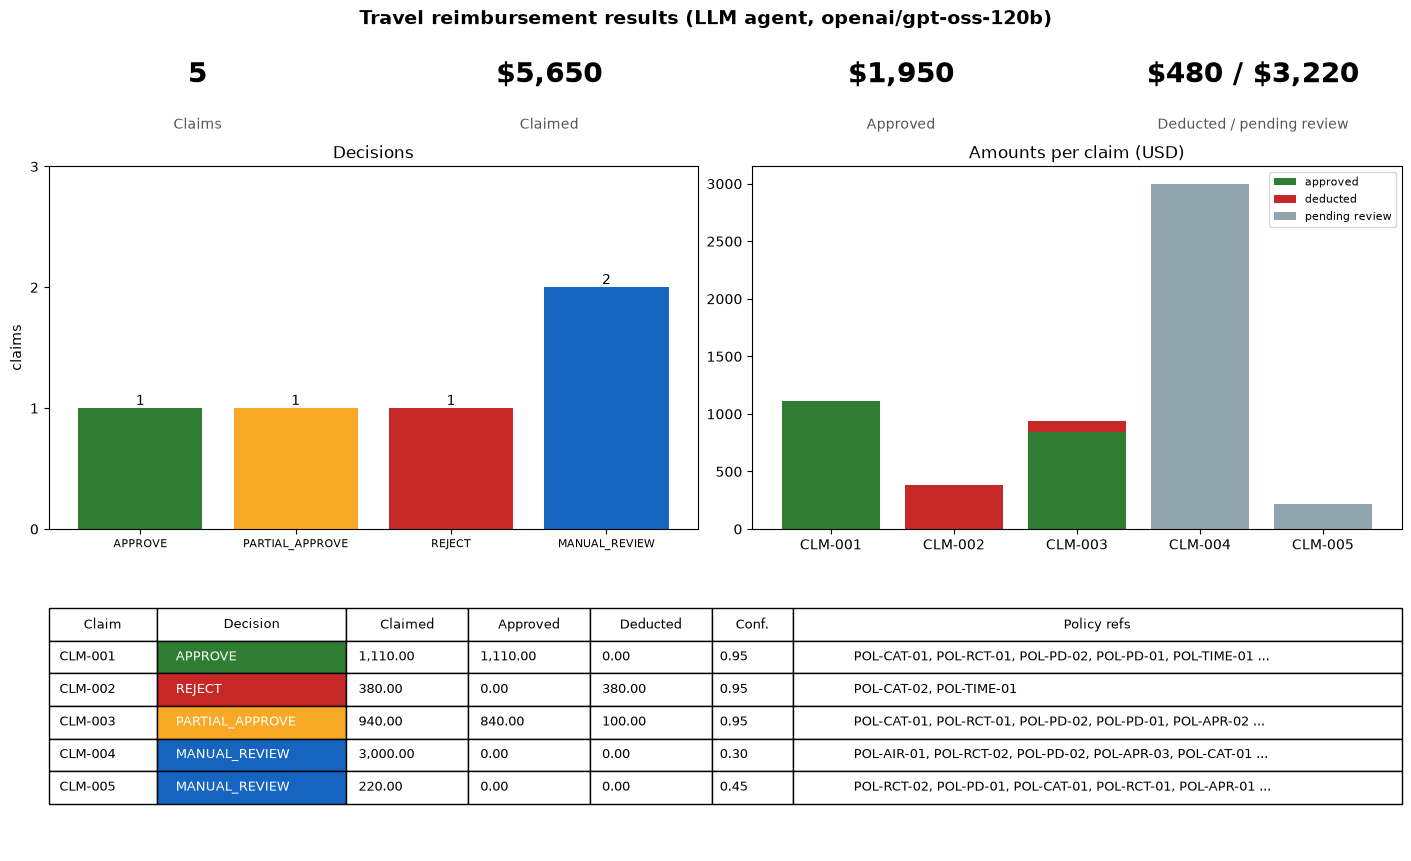

In [12]:
COLORS = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825", "REJECT": "#c62828", "MANUAL_REVIEW": "#1565c0"}

df = pd.DataFrame([r.model_dump() for r in RESULTS])
df["claimed"] = [CLAIMS_BY_ID[c].total for c in df.claim_id]
df["pending"] = (df.claimed - df.approved_amount - df.deducted_amount).round(2)

fig = plt.figure(figsize=(14, 8.5), constrained_layout=True)
mode = f"LLM agent, {GROQ_MODEL}" if USE_LLM else "rule engine"
fig.suptitle(f"Travel reimbursement results ({mode})", fontsize=14, fontweight="bold")
gs = fig.add_gridspec(3, 4, height_ratios=[0.55, 2, 1.6])

kpis = [("Claims", f"{len(df)}"),
        ("Claimed", f"${df.claimed.sum():,.0f}"),
        ("Approved", f"${df.approved_amount.sum():,.0f}"),
        ("Deducted / pending review", f"${df.deducted_amount.sum():,.0f} / ${df.pending.sum():,.0f}")]
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")
    ax.text(0.5, 0.62, value.replace("$", r"\$"), ha="center", va="center", fontsize=20, fontweight="bold")
    ax.text(0.5, 0.12, label, ha="center", va="center", fontsize=10, color="#555")

ax1 = fig.add_subplot(gs[1, :2])
counts = df.decision.value_counts().reindex(list(COLORS), fill_value=0)
bars = ax1.bar(counts.index, counts.values, color=list(COLORS.values()))
ax1.bar_label(bars)
ax1.set_title("Decisions")
ax1.set_ylabel("claims")
ax1.set_ylim(0, counts.max() + 1)
ax1.yaxis.get_major_locator().set_params(integer=True)
ax1.tick_params(axis="x", labelsize=8)

ax2 = fig.add_subplot(gs[1, 2:])
ax2.bar(df.claim_id, df.approved_amount, color="#2e7d32", label="approved")
ax2.bar(df.claim_id, df.deducted_amount, bottom=df.approved_amount, color="#c62828", label="deducted")
ax2.bar(df.claim_id, df.pending, bottom=df.approved_amount + df.deducted_amount, color="#90a4ae", label="pending review")
ax2.set_title("Amounts per claim (USD)")
ax2.legend(fontsize=8)

ax3 = fig.add_subplot(gs[2, :])
ax3.axis("off")
rows = []
for r, claimed in zip(RESULTS, df.claimed):
    refs = ", ".join(r.policy_refs[:5]) + (" ..." if len(r.policy_refs) > 5 else "")
    rows.append([r.claim_id, r.decision, f"{claimed:,.2f}", f"{r.approved_amount:,.2f}",
                 f"{r.deducted_amount:,.2f}", f"{r.confidence:.2f}", refs])
table = ax3.table(cellText=rows, colLabels=["Claim", "Decision", "Claimed", "Approved", "Deducted", "Conf.", "Policy refs"],
                  loc="center", cellLoc="left", colWidths=[0.08, 0.14, 0.09, 0.09, 0.09, 0.06, 0.45])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
for i, r in enumerate(RESULTS, start=1):
    table[i, 1].set_facecolor(COLORS[r.decision])
    table[i, 1].get_text().set_color("white")

fig.savefig("UI SS_1.png", dpi=110)
plt.show()

In [13]:
try:
    import ipywidgets as w
    from IPython.display import display

    picker = w.Dropdown(options=[(f"{c.claim_id}: {c.purpose}", c.claim_id) for c in CLAIMS] + [("Paste JSON below", "custom")],
                        description="Claim", layout=w.Layout(width="520px"))
    use_llm_box = w.Checkbox(value=USE_LLM, description="Use LLM agent", disabled=not (USE_LLM and AGENT_AVAILABLE))
    custom = w.Textarea(value=json.dumps(RAW_CLAIMS[2], indent=2).replace("CLM-003", "CLM-TEST"),
                        layout=w.Layout(width="720px", height="220px"))
    button = w.Button(description="Evaluate", button_style="primary")
    out = w.Output()

    def on_click(_):
        out.clear_output()
        with out:
            try:
                claim = Claim.model_validate_json(custom.value) if picker.value == "custom" else CLAIMS_BY_ID[picker.value]
            except ValidationError as exc:
                print("Invalid claim JSON:\n", exc)
                return
            r = evaluate_claim(claim, use_llm=use_llm_box.value)
            display(w.HTML(
                f"<h3 style='color:{COLORS[r.decision]};margin:4px 0'>{r.claim_id}: {r.decision}</h3>"
                f"<b>Approved:</b> ${r.approved_amount:,.2f} &nbsp; <b>Deducted:</b> ${r.deducted_amount:,.2f} "
                f"&nbsp; <b>Confidence:</b> {r.confidence:.2f}<br><b>Policy:</b> {', '.join(r.policy_refs)}"
                f"<br><b>Tools:</b> {', '.join(r.tools_used)}<p>{r.explanation}</p>"))
            print(json.dumps(r.model_dump(), indent=2))

    button.on_click(on_click)
    display(w.VBox([w.HBox([picker, use_llm_box, button]), custom, out]))
except ImportError:
    print("ipywidgets is not installed; the chart above is the dashboard.")

## Design Notes & Reasoning

### Approach

```
claim JSON -> Pydantic validation -> LLM agent (LangChain + Groq)
                                       calls tools by claim_id:
                                         policy_lookup, check_eligibility, check_receipts,
                                         check_per_diem_limits, check_approval_threshold, check_timeliness
                                       returns AgentDecision
                                   -> reconcile() against the rule engine -> ClaimResult
```

The tools do all calculations and the model decides what to check and explains the result. I chose this split because
reimbursement amounts have to be exact and repeatable, which is not something to leave to an LLM. The model is still
useful for choosing which rules apply, reading descriptions and writing a clear explanation. The rule engine is built
from the same tools, so it can check the agent's answer at little extra cost and keep the notebook running without an API key.

### Assumptions

- Nights and days come from the line item description and are checked against the trip dates. If the claim states
  more than the dates allow, I treat it as conflicting information and calculate the cap on the dates.
- Per-diem caps are applied per category for the whole claim (meals = $75 x days, lodging = $200 x nights), because
  the sample claims give one combined line per category.
- Line items have no individual dates, so the 30-day window is measured from the first day of the trip.
- The approval tier uses the total after deductions, as stated in section 4 of the policy. Business-class airfare is
  not deducted, because POL-AIR-01 says it should not be.
- MANUAL_REVIEW claims show 0 approved. Only definitely ineligible items are shown as deducted, and the explanation
  states what would be reimbursed if the claim is cleared.
- Confidence is how sure the agent is that the claim can be decided automatically. For manual review cases it goes
  down as more reasons apply.

### Why each claim gets its decision

| Claim | Decision | Reason |
|---|---|---|
| CLM-001 | APPROVE | All items eligible, $180/night and $60/day are under the caps, receipts attached, $1,110 is in the manager tier which counts as approvable |
| CLM-002 | REJECT | Spa and minibar are both POL-CAT-02, so nothing is reimbursable |
| CLM-003 | PARTIAL_APPROVE | Lodging is $250/night against $200, so $100 is deducted. The rest is compliant and $840 is in the manager tier |
| CLM-004 | MANUAL_REVIEW | Business-class airfare (POL-AIR-01), missing hotel receipt (POL-RCT-02), total over $2,000 (POL-APR-03), and 3 nights claimed on a trip that only covers 2 |
| CLM-005 | MANUAL_REVIEW | No receipt for a $220 meal (POL-RCT-02). It is also unclear whether the $75/day limit is per person for a client dinner for 4, so I don't deduct $145 automatically |

### Why manual review is used the way it is

The policy says to prefer manual review over forcing a decision. In code this means any exception, missing document,
conflict in the data, ambiguity not covered by the policy, a high total, a late claim, or a disagreement between the
agent and the rule checks sends the claim to a person. The cost is that some claims a person would approve quickly
still go to the queue. For a payments process I think that is the right trade-off.

### Trade-offs

| Decision | Benefit | Cost |
|---|---|---|
| Tools calculate, LLM orchestrates | Exact, repeatable amounts with a clear audit trail | More tool code; the LLM adds little on simple claims |
| Rule engine as cross-check and fallback | Catches wrong agent answers; runs without a key | Policy logic must be kept in line with the policy text |
| Disagreement goes to manual review | Safe; matches the policy guidance | Correct agent answers can be escalated unnecessarily |
| Keyword policy lookup instead of embeddings | 12 short rules, deterministic and easy to cite | Will not scale to a large policy manual |
| Groq free tier (gpt-oss-120b) | Free and fast, with good tool calling | Rate limits and occasional malformed tool calls, handled by retries and the fallback |

### Assumptions and limitations

- Receipts are not read. `receipt_attached` is taken as given.
- No duplicate detection across claims or employees, and no currency conversion.
- The ineligible keyword list is finite. An unusual description could pass it, although unknown categories still go
  to manual review.
- LLM explanations vary slightly between runs. Decisions and amounts are fixed by the validator.

### What I would improve next

1. Embedding-based retrieval for a longer policy, plus a check that each cited POL id actually supports the decision.
2. A larger evaluation set (late claims, ground transport, mixed eligible and ineligible items) run on every change.
3. Receipt OCR to compare vendor, date and amount with the line items.
4. Expose the tools through an MCP server so other applications can use them, and keep a persistent audit log.
5. Record reviewer decisions on manual review cases and use them as labelled examples for evaluation.

In [14]:
# Final results: one object per claim with the fields required in section 3 of the brief.
FIELDS = ["claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs",
          "policy_refs", "confidence", "explanation", "tools_used"]
final_results = [r.model_dump() for r in RESULTS]
assert all(list(r) == FIELDS for r in final_results)
print(json.dumps(final_results, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-RCT-01",
      "POL-PD-02",
      "POL-PD-01",
      "POL-TIME-01",
      "POL-APR-02",
      "POL-AIR-01"
    ],
    "confidence": 0.95,
    "explanation": "All line items are in eligible categories per POL-CAT-01, receipts are attached per POL-RCT-01, lodging and meals are within per-diem caps (POL-PD-02, POL-PD-01), the claim is within the 30-day submission window (POL-TIME-01), and the total reimbursable amount $1110.00 falls under the manager approval tier (POL-APR-02). No deductions are required.",
    "tools_used": [
      "policy_lookup",
      "check_eligibility",
      "check_receipts",
      "check_per_diem_limits",
      "check_approval_threshold",
      "check_timeliness"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_a